In [7]:
from pathlib import Path

import colorcet as cc
import equinox as eqx
import jax
import matplotlib.pyplot as plt
from dynamical_systems.continuous import Lorenz63, Lorenz96, solve_ode
from dynamical_systems.metrics import (
    cosine_similarity as cosine_similarity,
    maximum_mean_discrepancy as maximum_mean_discrepancy,
    root_mean_squared_error as root_mean_squared_error,
    sinkhorn_divergence as sinkhorn_divergence,
)
from dynamics_discovery.data import TimeSeriesDataset
from dynamics_discovery.io import load_model
from dynamics_discovery.models import NeuralODE
from tqdm import tqdm


plt.style.use("matplotlib_utils.styles.dash_gridded")
jax.config.update("jax_enable_x64", True)


EXP_TYPES_ALL = (
    "vanilla",
    "neighborhood",
    "efficient_neighborhood",
    "dyslim",
    "dyslim_neigh",
)
EXP_TYPES = (
    "efficient_neighborhood",
    "vanilla",
    # "neighborhood",
    "dyslim",
    # "dyslim_neigh",
)

COLOR_DICT = dict(
    zip(
        EXP_TYPES_ALL,
        (
            cc.cm.glasbey_dark(45),
            cc.cm.glasbey_dark(0),
            cc.cm.glasbey_dark(64),
            cc.cm.glasbey_dark(46),
            cc.cm.glasbey_dark(91),
        ),
    )
)
LABEL_DICT = dict(
    zip(
        EXP_TYPES_ALL,
        (
            "Vanilla",
            "Neighborhood (Ours)",
            "Neighborhood (Ours)",
            "DySLIM (ICML 2024)",
            "DySLIM - Neighborhood",
        ),
    )
)

ODE_DICT = {
    "lorenz63": Lorenz63(),
    "lorenz96_6d": Lorenz96(dim=6),
    "lorenz96_18d": Lorenz96(dim=18),
    "lorenz96_54d": Lorenz96(dim=54),
}

ODE_BURN_IN_DICT = {
    "lorenz63": (0, 50, 1.0),
    "lorenz96_6d": (0, 1000, 10.0),
    "lorenz96_18d": (0, 1000, 10.0),
    "lorenz96_54d": (0, 1000, 10.0),
}

ODE_LABEL_DICT = {
    "lorenz63": "Lorenz63",
    "lorenz96_6d": "Lorenz96 (6D)",
    "lorenz96_18d": "Lorenz96 (18D)",
    "lorenz96_54d": "Lorenz96 (54D)",
}

In [8]:
def load_experiment(
    dataset_name: str,
    exp_type: str,
    key: int,
    noise: float,
    rootdir=Path("../../results/revised/"),
) -> NeuralODE:
    loaddir = rootdir / dataset_name / exp_type / "best"
    model_path_template = f"*_noise={noise}_key={key}*"
    model_paths = list(loaddir.glob(model_path_template))
    if len(model_paths) == 0:
        raise ValueError("No models found with the given conditions")
    elif len(model_paths) > 1:
        raise ValueError("Multiple models found with the given conditions!")
    else:
        return load_model(model_paths[0])


def load_test_dataset(dataset_name: str, rootdir=Path("../../data")):
    standardizer = TimeSeriesDataset.from_hdf5(
        rootdir / f"{dataset_name}_train.hdf5", time_slice=slice(0, None, 2)
    ).standardize()[1]
    dataset_test = TimeSeriesDataset.from_hdf5(
        rootdir / f"{dataset_name}_test.hdf5", time_slice=slice(0, None, 2)
    ).apply_transform(standardizer)
    return dataset_test, standardizer

In [9]:
@eqx.filter_jit
def solve_batch(model, t, u0_batch, rtol=1e-4, atol=1e-6):
    def _solve(u0_):
        return solve_ode(model, t, u0_, rtol=rtol, atol=atol, max_steps=None)

    return eqx.filter_vmap(_solve)(u0_batch)


In [13]:
for dataset_name in ODE_DICT.keys():
    d = load_test_dataset(dataset_name)[0]
    print(1 / d.metadata["lyapunovs"][0])

1.1042523288193862
0.805923215756382
0.46974556082319935
0.42666023735246017


  0%|          | 0/3 [00:00<?, ?it/s]W0418 22:38:25.481120 2555500 hlo_rematerialization.cc:3233] Can't reduce memory use below 15.71GiB (16872555023 bytes) by rematerialization; only reduced to 18.63GiB (20004194320 bytes), down from 18.63GiB (20004194320 bytes) originally
W0418 22:38:25.481284 2555506 hlo_rematerialization.cc:3233] Can't reduce memory use below 15.71GiB (16872555023 bytes) by rematerialization; only reduced to 18.63GiB (20004194320 bytes), down from 18.63GiB (20004194320 bytes) originally
W0418 22:38:25.481312 2555512 hlo_rematerialization.cc:3233] Can't reduce memory use below 15.71GiB (16872555023 bytes) by rematerialization; only reduced to 18.63GiB (20004194320 bytes), down from 18.63GiB (20004194320 bytes) originally
W0418 22:38:25.481768 2555500 hlo_rematerialization.cc:3233] Can't reduce memory use below 15.71GiB (16872555023 bytes) by rematerialization; only reduced to 18.63GiB (20004194320 bytes), down from 18.63GiB (20004194320 bytes) originally
W0418 22:38

JaxRuntimeError: INTERNAL: Autotuning failed for HLO: %cublas-batch-gemm.8 = (f64[50,5000,5000]{2,1,0}, s8[4194304]{0}) custom-call(%get-tuple-element.146, %get-tuple-element.146, %add.299), custom_call_target="__cublas$gemm", output_to_operand_aliasing={{0}: (2, {})}, metadata={op_name="jit(scan)/while/body/closed_call/vmap(jit(sinkhorn_divergence))/while/body/while/body/closed_call/vmap(vmap())/dot_general" stack_frame_id=3758}, backend_config={"operation_queue_id":"0","wait_on_operation_queues":[],"gemm_backend_config":{"alpha_real":-2,"beta":1,"dot_dimension_numbers":{"lhs_contracting_dimensions":["2"],"rhs_contracting_dimensions":["2"],"lhs_batch_dimensions":["0"],"rhs_batch_dimensions":["0"]},"alpha_imag":0,"precision_config":{"operand_precision":["DEFAULT","DEFAULT"],"algorithm":"ALG_UNSET"},"epilogue":"DEFAULT","lhs_stride":"30000","rhs_stride":"30000","grad_x":false,"grad_y":false,"damax_output":false,"autotune_workspace_size":"0"},"force_earliest_schedule":false,"reification_

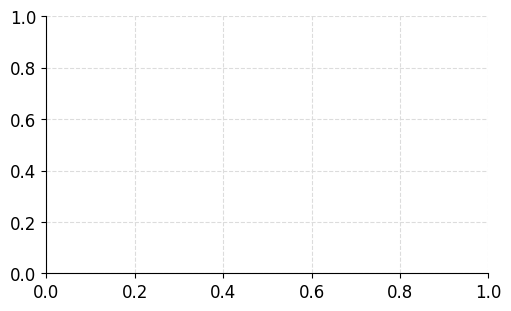

In [5]:
import jax.numpy as jnp


dataset_name = "lorenz96_6d"

dataset_test, standardize = load_test_dataset(dataset_name)
ode_true = ODE_DICT[dataset_name]
u0_test = solve_batch(
    ode_true,
    jnp.arange(*ODE_BURN_IN_DICT[dataset_name]),
    jax.random.normal(jax.random.key(0), (5000, ode_true.dim)),
    rtol=1e-8,
    atol=1e-10,
)[:, -1]

u_test = solve_batch(ode_true, dataset_test.t[0, ::20], u0_test, rtol=1e-8, atol=1e-10)
u_test = standardize(u_test)

fig, ax = plt.subplots(1, 1, figsize=(5, 3))
for exp_type in tqdm(EXP_TYPES):
    model = load_experiment(dataset_name, exp_type, 0, 0.1)

    u_pred = solve_batch(model, dataset_test.t[0, ::20], u_test[0])
    sinkhorns = jax.lax.map(
        lambda x: sinkhorn_divergence(*x),
        (jnp.permute_dims(u_pred, (1, 0, 2)), jnp.permute_dims(u_test, (1, 0, 2))),
        batch_size=50,
    )
    ax.plot(
        jnp.arange(len(dataset_test.t[0, ::20])) * 0.2,
        sinkhorns,
        label=LABEL_DICT[exp_type],
        color=COLOR_DICT[exp_type],
    )

In [29]:
model = load_experiment("lorenz63", "dyslim", 0, 0.1)
u_pred = solve_batch(model, dataset_test.t[0, ::10], u0_test)

In [30]:
u_pred.shape

(2500, 500, 3)

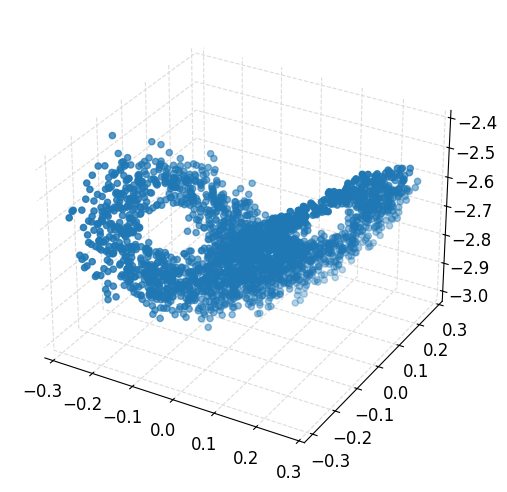

In [37]:
fig, ax = plt.subplots(1, 1, subplot_kw={"projection": "3d"})
ax.scatter(*standardize(u_test[:, 100]).T)

In [33]:
standardize(u0_test)

Array([[-1.24496165, -0.52692872,  1.20985992],
       [-1.8869818 , -1.91281031,  1.14079405],
       [ 1.62580039,  0.90687997,  1.58095326],
       ...,
       [-0.57917599, -0.78682953, -0.84285321],
       [ 0.41893227,  0.07729316,  0.23055709],
       [ 0.57307766,  0.62912175, -0.40542372]], dtype=float64)